# Module 1 — Data Audit

This notebook audits four seasons of NBA player game logs pulled from `nba_api` and produces a clean dataset ready for feature engineering. The audit follows a five-step framework: scope, integrity, column quality, value sanity, and time structure. Each step ends with an explicit decision (keep, drop, transform, or flag) rather than silent handling, because silent handling is how invisible bugs enter production pipelines.

The guiding principle: audits surface decisions, not bugs. A null value is not a problem — it is a decision point.

**Input:** raw player game logs from `nba_api` (2021–22 through 2024–25 seasons).
**Output:** `data/processed/model_df.parquet` — 104,641 rows, 925 unique players, sorted chronologically per player.

## The universal 5-step data audit framework

Every dataset you ever work with in your career goes through these same 5 questions. **Memorize the pattern, not the pandas syntax.** The questions are the same for every dataset. The code is lookup-able.

| Step | Question you're answering | Decision you make | Common pandas tools |
|---|---|---|---|
| **1. Scope** | What's in this data? How much? What's one row? | What's the natural "grain" (one row per *what*)? | `df.shape`, `df.head()`, `df['col'].nunique()`, `df['date'].min()/.max()` |
| **2. Integrity** | Any duplicates that shouldn't exist? | Drop, merge, or investigate duplicates? | `df.duplicated(subset=[...]).sum()` |
| **3. Column quality** | Which columns are good features vs junk vs leakage? | Drop, keep, or transform each column? | `df.dtypes`, `df.isna().mean()`, `df.nunique()` |
| **4. Value sanity** | Are the actual values plausible? Any impossible numbers or outliers? | Keep outliers, cap them, or drop them? | `df.describe()`, histograms, `df['col'].value_counts()` |
| **5. Structure** | Does the data's shape match reality? (chronology, logical consistency) | Fix or flag before modeling | `.sort_values()`, `.groupby().diff()`, custom checks |

**Where our 6 questions sit:**
- **Q1** → Step 1 + a slice of Step 2 (shape, counts, duplicates)
- **Q2** → Step 3 (column quality — dtypes, NaN %, uniqueness)
- **Q3** → Step 4 (DNP detection — value sanity on `MIN`)
- **Q4** → Step 5 (mid-season trades — structural inconsistency)
- **Q5** → Step 5 (chronological integrity, gap detection)
- **Q6** → Step 1 revisited (defining the target variable)

### How this transfers to other projects

| Domain | Grain (step 1) | Duplicate check (step 2) | Leakage column (step 3) |
|---|---|---|---|
| Retail transactions | one row per transaction | `subset=['transaction_id']` | `was_fraud` if predicting fraud |
| Hospital visits | one row per visit | `subset=['patient_id', 'visit_timestamp']` | `discharge_diagnosis` if predicting admission |
| Stock prices | one row per (ticker, timestamp) | `subset=['ticker', 'timestamp']` | future-dated features |
| **Our dataset** | one row per (player, game) | `subset=['PLAYER_ID', 'GAME_ID']` | `FANTASY_PTS` (it IS the target) |

Same framework. Different domain. Same 5 questions.

## Setup

Imports and loading. Load both parquet files into DataFrames named `pg` (player games) and `tg` (team games).

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.width', 180)
pd.set_option('display.max_columns', 40)

pg = pd.read_parquet('data/raw/player_games_2021_2024.parquet')
tg = pd.read_parquet('data/raw/team_games_2021_2024.parquet')


## Q1 — Shape, provenance, duplicates

**Find and print:**
- row count, column count
- unique players, unique games, unique seasons
- date range (min, max)
- any duplicate rows on `(PLAYER_ID, GAME_ID)` — if yes, what caused them?

**Why this matters:** before you build anything, you need to know what "one row" actually means in this table. Duplicate (player, game) pairs would silently inflate rolling averages.

**Gotcha to watch for:** there's one scenario where a (player, game) duplicate *could* legitimately appear in nba_api data. Think about it — doesn't mean it's in our file, but your audit should check.

In [74]:
print(f"rows: {pg.shape[0]:,}   cols: {pg.shape[1]}")
print(f"unique players: {pg['PLAYER_ID'].nunique()}")
print(f"unique games:   {pg['GAME_ID'].nunique()}")
print(f"unique seasons: {pg['SEASON'].nunique()}")
print(f"date range:     {pg['GAME_DATE'].min()}  →  {pg['GAME_DATE'].max()}")
pg.duplicated(subset=['PLAYER_ID','GAME_ID']).sum()
"""**Q1 insight:** Dataset is clean on the shape axis — 104k rows across 4 full regular seasons (2021-22 → 2024-25),
no games missing (4920 = 4 × 1230 ✓), zero duplicate (player, game) pairs. We don't need to deduplicate before training."""

rows: 104,641   cols: 34
unique players: 925
unique games:   4920
unique seasons: 4
date range:     2021-10-19 00:00:00  →  2025-04-13 00:00:00


"**Q1 insight:** Dataset is clean on the shape axis — 104k rows across 4 full regular seasons (2021-22 → 2024-25),\nno games missing (4920 = 4 × 1230 ✓), zero duplicate (player, game) pairs. We don't need to deduplicate before training."

## Q2 — Column-level audit

For every column, print: **dtype**, **% NaN**, **# distinct values**. Then flag:
- any column that's all-same (zero variance → useless feature)
- any column with suspiciously high NaN %
- any column that's clearly redundant with another

**Why this matters:** every one of these columns is a potential feature. You need to know their quality before you spend time engineering them.

**Hint I'll give because it's a judgement call:** `FG_PCT`, `FG3_PCT`, `FT_PCT` are *derived* from the other columns. Not necessarily bad, but worth noting.

In [7]:
# Q2
audit = pd.DataFrame({
    'dtype':pg.dtypes,
    'nan_pct':pg.isna().mean() * 100,
    'n_unique':pg.nunique()
})
audit

,dtype,nan_pct,n_unique
SEASON_ID,str,0.000000,4
PLAYER_ID,int64,0.000000,925
PLAYER_NAME,str,0.000000,925
TEAM_ID,int64,0.000000,30
TEAM_ABBREVIATION,str,0.000000,30
TEAM_NAME,str,0.000000,30
GAME_ID,str,0.000000,4920
GAME_DATE,datetime64[us],0.000000,652
MATCHUP,str,0.000000,1740
WL,str,0.000000,2


## Q3 — DNP detection

**Produce:**
- a histogram of `MIN` (minutes played)
- a verdict: where should the "this is a DNP/garbage-time, exclude from training" cutoff go? Justify in a comment.

**Why this matters:** box-score models trained on 2-minute garbage-time appearances will have massive variance and skew the baseline. But cutting too aggressively throws away real role-player signal.

**Edge case to specifically check:** are there any rows with `MIN == 0` that have **nonzero** stats? What are those? (Hint: nba_api can emit a specific type of row for players who were on the roster but didn't actually enter the game.)

,SEASON_ID,PLAYER_ID,PLAYER_NAME,TEAM_ID,TEAM_ABBREVIATION,TEAM_NAME,GAME_ID,GAME_DATE,MATCHUP,WL,MIN,FGM,FGA,FG_PCT,FG3M,FG3A,FG3_PCT,FTM,FTA,FT_PCT,OREB,DREB,REB,AST,STL,BLK,TOV,PF,PTS,PLUS_MINUS,FANTASY_PTS,VIDEO_AVAILABLE,SEASON
30045,22022,1630700,Dyson Daniels,1610612740,NOP,New Orleans Pelicans,0022200191,2022-11-12,NOP vs. HOU,W,0,0,0,NaN,0,0,NaN,2,2,1.0,0,0,0,0,0,0,0,0,2,0,2.0,1,2022-23
34067,22022,1630553,Keon Johnson,1610612757,POR,Portland Trail Blazers,0022200376,2022-12-08,POR vs. DEN,L,0,1,1,1.0,1,1,1.0,0,0,NaN,0,0,0,0,0,0,0,0,3,1,3.0,1,2022-23
51921,22022,1631111,Wendell Moore Jr.,1610612750,MIN,Minnesota Timberwolves,0022201225,2023-04-09,MIN vs. NOP,W,0,1,1,1.0,0,0,NaN,0,0,NaN,1,0,1,0,0,0,0,0,2,2,3.2,1,2022-23
68071,22023,1630692,Jordan Goodwin,1610612756,PHX,Phoenix Suns,0022300725,2024-02-06,PHX vs. MIL,W,0,0,0,NaN,0,0,NaN,2,2,1.0,0,0,0,0,0,0,0,0,2,-3,2.0,1,2023-24
68861,22023,1631115,Orlando Robinson,1610612748,MIA,Miami Heat,0022300759,2024-02-11,MIA vs. BOS,L,0,0,0,NaN,0,0,NaN,2,2,1.0,0,0,0,0,0,0,0,0,2,0,2.0,1,2023-24
91660,22024,1642353,Cam Christie,1610612746,LAC,LA Clippers,0022400596,2025-01-19,LAC vs. LAL,W,0,0,0,NaN,0,0,NaN,1,2,0.5,0,0,0,0,0,0,0,0,1,-1,1.0,1,2024-25
100148,22024,1642402,Enrique Freeman,1610612754,IND,Indiana Pacers,0022400986,2025-03-17,IND @ MIN,W,0,0,0,NaN,0,0,NaN,2,2,1.0,0,0,0,0,0,0,0,0,2,-1,2.0,1,2024-25
100196,22024,1642384,Isaiah Crawford,1610612758,SAC,Sacramento Kings,0022400992,2025-03-17,SAC vs. MEM,W,0,0,0,NaN,0,0,NaN,1,2,0.5,0,0,0,0,0,0,0,1,1,3,1.0,1,2024-25


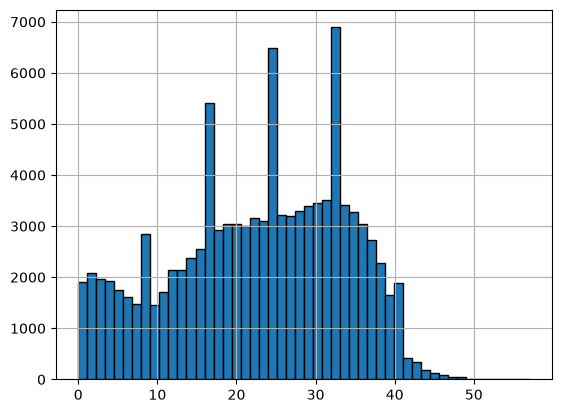

In [49]:
pg["MIN"].hist(bins=50, edgecolor="black")
pg[(pg['MIN'] == 0) & (pg['PTS'] > 0)]

## Q4 — Mid-season trades

**Find and print:**
- how many `(PLAYER_NAME, SEASON)` pairs appear with more than one `TEAM_ABBREVIATION`?
- top 5 traded players by # of games split across teams, within one season

**Why this matters:** when we build rolling features ("your average over the last 10 games"), a traded player's last 10 games span two different teams, systems, and roles. We don't fix it in this module — but your audit must *surface* it so we know it's lurking.

**Think about:** is there anything in the data that lets us know *which game was the first game with the new team*? If not, how might we infer it?

In [50]:
teams_per_player_season = pg.groupby(['PLAYER_NAME', 'SEASON'])['TEAM_ABBREVIATION'].nunique()
traded = teams_per_player_season[teams_per_player_season > 1]
traded
print(f"Number of (player, season) pairs that got traded mid-season: {len(traded)}")
print(f"\nTraded players (sorted by number of teams, then alphabetically):")
print(traded.sort_values(ascending=False).head(15))


Number of (player, season) pairs that got traded mid-season: 326

Traded players (sorted by number of teams, then alphabetically):
PLAYER_NAME         SEASON 
Greg Monroe         2021-22    4
Kenneth Lofton Jr.  2023-24    3
Shake Milton        2023-24    3
Tomas Satoransky    2021-22    3
Luke Kornet         2021-22    3
Malachi Flynn       2023-24    3
Jeff Dowtin Jr.     2021-22    3
MarJon Beauchamp    2024-25    3
James Ennis III     2021-22    3
Danilo Gallinari    2023-24    3
Tristan Thompson    2021-22    3
Danuel House Jr.    2021-22    3
David Roddy         2024-25    3
Mike Muscala        2023-24    3
Isaiah Thomas       2021-22    3
Name: TEAM_ABBREVIATION, dtype: int64


## Q5 — Chronological integrity

**Verify:**o
- after sorting by `(PLAYER_ID, GAME_DATE)`, is each player's log monotonically increasing in time? (It should be — but confirm.)
- count players with at least one **mid-season gap of 30+ days** per season. (A big gap usually = injury return. We'll want to flag these later.)
- is the overall dataset's time axis continuous within each season? Any suspicious gaps across the whole league (e.g., covid pauses, all-star break)?

**Why this matters:** every rolling-window feature we build assumes rows are chronologically ordered within a player. Any failure here is a silent catastrophe downstream.

In [66]:
# 1. Get all unique game dates in the dataset, sorted ascending
unique_dates = pd.Series(sorted(pg['GAME_DATE'].unique()))

# 2. Pair each date with the gap in days since the previous league game-day
league_gaps = pd.DataFrame({
    'date': unique_dates,
    'days_since_prev': unique_dates.diff().dt.days
})

# 3. Show the 15 biggest gaps
print(league_gaps.sort_values('days_since_prev', ascending=False).head(15))


          date  days_since_prev
329 2023-10-24            198.0
489 2024-10-22            191.0
165 2022-10-18            191.0
120 2022-02-24              7.0
284 2023-02-23              7.0
438 2024-02-22              7.0
599 2025-02-19              6.0
372 2023-12-11              3.0
543 2024-12-19              3.0
548 2024-12-25              2.0
367 2023-12-04              2.0
385 2023-12-25              2.0
65  2021-12-25              2.0
230 2022-12-25              2.0
651 2025-04-13              2.0


## Q6 — Compute the target variable

**Build and apply YOUR league's scoring:**
```
PTS +1, FGM +2, FGA -1, FTM +1, FTA -1, 3PM +1, REB +1, AST +2, STL +4, BLK +4, TOV -2
```

Add it to `pg` as a column named `FP`. Then print:
- FP overall: mean, median, p90, p99, max
- FP mean by SEASON — did scoring environment drift?
- Top 5 single-game FP performances across all 4 seasons (player, date, matchup, FP)

**Sanity check:** compare your `FP` against the `FANTASY_PTS` column that's already in the parquet (nba_api's built-in default scoring). They *shouldn't* match — but they should correlate strongly (>0.95). If correlation is weirdly low, you have a weight mapped to the wrong column.


In [73]:
pg['FP'] = (
    pg['PTS'] * 1 +
    pg['FGM'] * 2 +
    pg['FGA'] *-1 +
    pg['FTM'] * 1 +
    pg['FTA'] *-1 +
    pg['FG3M'] *1 +
    pg['REB'] * 1 +
    pg['AST'] * 2 +
    pg['STL'] * 4 +
    pg['BLK'] * 4 +
    pg['TOV'] *-2
)
print(f"FP mean:   {pg['FP'].mean():.2f}")
print(f"FP median: {pg['FP'].median():.2f}")
print(f"FP p90:    {pg['FP'].quantile(0.90):.2f}")
print(f"FP p99:    {pg['FP'].quantile(0.99):.2f}")
print(f"FP max:    {pg['FP'].max():.2f}")
print()
print("FP mean by season:")
print(pg.groupby('SEASON')['FP'].mean())
pg.nlargest(10, 'FP')[['PLAYER_NAME', 'GAME_DATE', 'TEAM_ABBREVIATION', 'FP']]


FP mean:   22.08
FP median: 20.00
FP p90:    46.00
FP p99:    69.00
FP max:    119.00

FP mean by season:
SEASON
2021-22    21.566727
2022-23    22.089747
2023-24    22.301958
2024-25    22.375162
Name: FP, dtype: float64


,PLAYER_NAME,GAME_DATE,TEAM_ABBREVIATION,FP
61207,Luka Dončić,2023-12-25,DAL,119
66298,Luka Dončić,2024-01-26,DAL,117
30204,Joel Embiid,2022-11-13,PHI,115
36795,Luka Dončić,2022-12-27,DAL,112
102477,Stephen Curry,2025-04-01,GSW,111
20513,Nikola Jokić,2022-03-06,DEN,110
65660,Joel Embiid,2024-01-22,PHI,110
37799,Donovan Mitchell,2023-01-02,CLE,109
82069,Giannis Antetokounmpo,2024-11-13,MIL,109
86592,Luka Dončić,2024-12-15,DAL,109


## Reflection — 3 bullets

Before you call this module done, write below:

1. **Three things in this dataset you'll have to handle carefully when building features.** (Not "the data has NaN." Be specific — "trades split rolling windows," "DNPs cluster at MIN<X minutes," etc.)
2. **One hypothesis you want to test with features later** — e.g., "players on back-to-backs lose ~Y FP."
3. **One question about the data you still don't know the answer to.**

Then call me back and I'll review.

In [ ]:
# Your 3-bullet reflection as a comment block or print statements:
